# 02 · Labels: the tree and the label space

Two objects describe the labels:

* the **label tree** (`LabelTree`, `nxgen/core/tree.py`): the ontology that drives the
  intensity model. It says which labels share intensities and at which resolution two
  structures can be told apart;
* the **label space** (`LabelSpace`, `nxgen/core/label_space.py`): the list of output labels
  and the mapping between raw label values (e.g. 2002) and the indices 0..K-1 used inside the
  generator and in the saved segmentations.

In [1]:
from _setup import *
import json
from nxgen.core.tree import LabelTree
from nxgen.core.label_space import LabelSpace
import phantoms                       # the small test tree (tests/phantoms.py)

## 1. The tree format

A tree is a JSON file with a list of principal **colors** (e.g. GM, WM, CSF), optional
**contrasts**, and **nodes**. Each node has:

| field | meaning |
|---|---|
| `parent`, `children`, `level` | the hierarchy (root = level 0) |
| `labels` | raw label values painted with this node's Gaussian |
| `w_mu`, `w_sigma` | **level 1 only**: weights of the principal colors (sum to 1) |
| `wr_mu`, `wr_sigma` | weight of the random part of the mean / std |
| `r_max` | coarsest voxel size (mm) at which the node is visible: `null` (always), a number, or `{"default": x, "T2": y}` |
| `null` | the node and its subtree get intensity 0 (e.g. background) |

The small tree of the tests shows every feature:

In [2]:
print(json.dumps(phantoms.TREE, indent=1))

{
 "version": "test",
 "description": "phantom tree",
 "colors": [
  "GM",
  "WM",
  "CSF"
 ],
 "contrasts": [
  "T1",
  "T2"
 ],
 "root": "root",
 "nodes": {
  "root": {
   "parent": null,
   "children": [
    "background",
    "csf",
    "gm",
    "wm"
   ],
   "level": 0,
   "labels": []
  },
  "background": {
   "parent": "root",
   "children": [],
   "level": 1,
   "labels": [
    0
   ],
   "null": true
  },
  "csf": {
   "parent": "root",
   "children": [],
   "level": 1,
   "labels": [
    24
   ],
   "w_mu": [
    0,
    0,
    1
   ],
   "wr_mu": 5.0,
   "wr_sigma": 0.5
  },
  "gm": {
   "parent": "root",
   "children": [
    "gm_part"
   ],
   "level": 1,
   "labels": [
    3
   ],
   "w_mu": [
    1,
    0,
    0
   ],
   "wr_mu": 5.0,
   "wr_sigma": 0.5
  },
  "gm_part": {
   "parent": "gm",
   "children": [],
   "level": 2,
   "labels": [
    42
   ],
   "wr_mu": 20.0,
   "wr_sigma": 0.5,
   "r_max": {
    "default": 1.0,
    "T2": 2.0
   }
  },
  "wm": {
   "parent": "ro

In [13]:
toy = phantoms.tree()
toy.print_tree()

root [L0, r_max=inf, visible]
    background [L1, r_max=inf, visible] labels=[0]
    csf [L1, r_max=inf, visible] labels=[24]
    gm [L1, r_max=inf, visible] labels=[3]
        gm_part [L2, r_max=1, visible] labels=[42]
    wm [L1, r_max=inf, visible] labels=[2]


## 2. The NextBrain tree

In [4]:
tree = LabelTree.from_json(TREE)
levels = {}
for n in tree.nodes.values():
    levels[n.level] = levels.get(n.level, 0) + 1
print('colors   :', tree.colors)
print('contrasts:', tree.contrasts)
print('nodes per level:', dict(sorted(levels.items())))
print('labels   :', len(tree.label_to_node))
print('level-1 nodes:', [n for n in tree.order() if tree.nodes[n].level == 1])

colors   : ['Brainstem', 'CSF / ventricles', 'Cerebellar GM', 'Cerebellar WM', 'Cerebral GM', 'Cerebral WM', 'Deep GM', 'Other']
contrasts: ['T1', 'T2', 'FLAIR', 'PD']
nodes per level: {0: 1, 1: 9, 2: 19, 3: 30, 4: 73, 5: 335}
labels   : 335
level-1 nodes: ['background_l1', 'brainstem_l1', 'csf_ventricles_l1', 'cerebellar_gm_l1', 'cerebellar_wm_l1', 'cerebral_gm_l1', 'cerebral_wm_l1', 'deep_gm_l1', 'other_l1']


In [5]:
# the subtree of the cerebral grey matter, at full resolution
def print_subtree(tree, name, depth=0, max_depth=3, res=None):
    n = tree.nodes[name]
    vis = tree.visibility(res)[name]
    r = n.r_max_for(None)
    print('    ' * depth + f'{name}  [L{n.level}, r_max={r:g}{"" if vis else ", collapsed"}]'
          + (f' labels={n.labels[:5]}{"..." if len(n.labels) > 5 else ""}' if n.labels else ''))
    if depth < max_depth:
        for c in n.children[:6]:
            print_subtree(tree, c, depth + 1, max_depth, res)
        if len(n.children) > 6:
            print('    ' * (depth + 1) + f'... {len(n.children) - 6} more')

print_subtree(tree, 'cerebral_gm_l1')

cerebral_gm_l1  [L1, r_max=inf]
    amygdala_l2  [L2, r_max=2]
        amygdala_l3  [L3, r_max=0.5]
            anterior_amygdaloid_area_l4  [L4, r_max=0.5]
            basolateral_group_l4  [L4, r_max=0.5]
            central_group_l4  [L4, r_max=0.5]
            corticomedial_group_l4  [L4, r_max=0.5]
            transition_areas_l4  [L4, r_max=0.5]
            whole_amygdala_unassigned_l4  [L4, r_max=0.5]
    cerebral_cortex_l2  [L2, r_max=4]
        cerebral_cortex_l3  [L3, r_max=0.4]
            cingulate_cortex_l4  [L4, r_max=0.4]
            frontal_lobe_l4  [L4, r_max=0.4]
            insula_l4  [L4, r_max=0.4]
            occipital_lobe_l4  [L4, r_max=0.4]
            parietal_lobe_l4  [L4, r_max=0.4]
            temporal_lobe_l4  [L4, r_max=0.4]
        paleocortex_l3  [L3, r_max=0.5]
            olfactory_piriform_cortex_l4  [L4, r_max=0.5]
    hippocampal_formation_l2  [L2, r_max=2]
        hippocampus_l3  [L3, r_max=0.5]
            alveus_l4  [L4, r_max=0.5]
            c

## 3. Visibility and generation classes

A node of level ≥ 2 is **visible** at resolution `r` (mm) and contrast `c` if
`r <= r_max(c)` **and** its parent is visible. Level-1 nodes are always visible.

A node that is not visible uses the Gaussian of its deepest visible ancestor, its
**representative**. All labels with the same representative share one Gaussian in that image:
they form a **generation class**. The network cannot tell them apart in that image, so WP4 merges
them in the loss.

With the toy tree: `gm_part` has `r_max = 1 mm` (2 mm for T2).

In [6]:
for res, contrast in [(0.8, None), (1.5, None), (1.5, 'T2'), (3.0, 'T2')]:
    print(f'res {res} mm, contrast {contrast}:', toy.label_groups(res, contrast))

res 0.8 mm, contrast None: {'background': [0], 'wm': [2], 'gm': [3], 'csf': [24], 'gm_part': [42]}
res 1.5 mm, contrast None: {'background': [0], 'wm': [2], 'gm': [3, 42], 'csf': [24]}
res 1.5 mm, contrast T2: {'background': [0], 'wm': [2], 'gm': [3], 'csf': [24], 'gm_part': [42]}
res 3.0 mm, contrast T2: {'background': [0], 'wm': [2], 'gm': [3, 42], 'csf': [24]}


On NextBrain, the number of generation classes drops quickly as the resolution gets coarser:

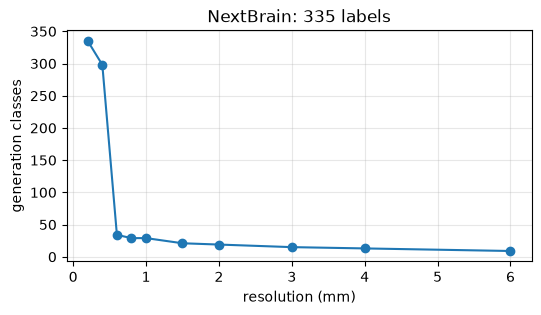

{0.2: 335, 0.4: 298, 0.6: 34, 0.8: 29, 1.0: 29, 1.5: 21, 2.0: 19, 3.0: 15, 4.0: 13, 6.0: 9}


In [18]:
resolutions = [0.2, 0.4, 0.6, 0.8, 1.0, 1.5, 2.0, 3.0, 4.0, 6.0]
counts = [len(tree.label_groups(r)) for r in resolutions]
plt.figure(figsize=(6, 3))
plt.plot(resolutions, counts, 'o-')
plt.xlabel('resolution (mm)'); plt.ylabel('generation classes')
plt.title(f'NextBrain: {len(tree.label_to_node)} labels'); plt.grid(alpha=.3)
plt.show()
print(dict(zip(resolutions, counts)))

The resolution used for visibility comes from the simulated acquisition (notebook 04). It is the
**coarsest** spacing: a structure must be resolved along every axis. An image with 0.4 × 0.4 × 3
mm voxels uses 3 mm.

## 4. The label space

Inside the generator, label maps hold **indices**, not raw values:

* index 0 is the background;
* index `i` is raw value `labels.values[i]`.

Why: NextBrain raw values go up to 2035. With contiguous indices, lookup tables have K entries
(not 2036), int16 is enough, and the saved segmentations have the contiguous labels nnU-Net
requires.

`LabelSpace.build(tree, template_values, background, output_labels, unassigned)`:

* `output_labels='templates'`: keep the labels found in the templates (and in the tree);
  `'tree'`: keep every tree label (some may never appear);
* `unassigned='error'`: a template label missing from the tree raises;
  `'background'`: it is mapped to index 0.

In [21]:
from nxgen.core.io import load_labels
seg, affine, voxel = load_labels(SOURCE_MAP)
values = set(np.unique(seg).tolist())
ls = LabelSpace.build(tree, values, background=0, output_labels='templates', unassigned='error')
ls_tree = LabelSpace.build(tree, values, output_labels='tree')
print('raw values in case-1      :', len(values))
print("output_labels='templates' :", len(ls), 'labels')
print("output_labels='tree'      :", len(ls_tree), 'labels')
print('first entries (index, raw value, name):')
for i in range(6):
    print('  ', i, ls.values[i], ls.names[i])

raw values in case-1      : 300
output_labels='templates' : 300 labels
output_labels='tree'      : 335 labels
first entries (index, raw value, name):
   0 0 background
   1 7 white_matter_of_forebrain
   2 48 head_of_caudate
   3 50 anterior_horn_of_lateral_ventricle
   4 68 septum_pellucidum
   5 79 putamen


Names are unique: the tree node name, plus the raw value when a node paints several labels.

### Converting raw values ↔ indices

In [9]:
lut = ls.lut(int(seg.max()))                       # raw value -> index (int16 tensor)
print('lut size:', lut.shape[0], ' raw 2002 ->', int(lut[2002]), ' raw 1 (not in space) ->', int(lut[1]))
idx = lut[torch.as_tensor(seg[200:203, 400, 300])]
print('indices :', idx.tolist())
print('back    :', ls.to_raw(idx).tolist(), '   original:', seg[200:203, 400, 300].tolist())

lut size: 2003  raw 2002 -> 299  raw 1 (not in space) -> 0
indices : [1, 1, 1]
back    : [7, 7, 7]    original: [7, 7, 7]


### Label groups

Several config keys take **label groups** (e.g. morphology pairs, adjacency rules). A group is a
tree node name (all labels of its subtree), a raw value, or a list of those. `resolve` turns a
group into indices. Labels absent from the label space are ignored.

In [29]:
for group in ['cerebral_gm_l1', 'cerebral_cortex_l2', 'csf_ventricles_l1', 2002, ['deep_gm_l1', 'brainstem_l1']]:
    idx = ls.resolve(group, tree)
    print(f'{str(group):40s} -> {len(idx):3d} indices, e.g. raw {[ls.values[i] for i in idx[:6]]}')

cerebral_gm_l1                           ->  72 indices, e.g. raw [99, 113, 125, 157, 214, 215]
cerebral_cortex_l2                       ->   5 indices, e.g. raw [99, 113, 125, 157, 2002]
csf_ventricles_l1                        ->   2 indices, e.g. raw [50, 68]
2002                                     ->   1 indices, e.g. raw [2002]
['deep_gm_l1', 'brainstem_l1']           -> 209 indices, e.g. raw [48, 79, 100, 101, 102, 103]


### Unassigned labels

In [11]:
try:
    LabelSpace.build(tree, values | {9999}, unassigned='error')
except ValueError as e:
    print('error:', e)
ls_bg = LabelSpace.build(tree, values | {9999}, unassigned='background')
print("with 'background': 9999 in the space?", 9999 in ls_bg.values,
      '-> lut maps it to', int(ls_bg.lut(9999)[9999]))

error: Template labels [9999] are not in the tree. Add them to the tree or set labels.unassigned = 'background'.
with 'background': 9999 in the space? False -> lut maps it to 0


### A frozen label space per dataset

The CLI saves the label space as `label_space.json` in the dataset the first time it runs and
loads it in later runs, so an index always means the same label, even if a later run uses other
templates. (v2 rebuilt it in every run: `problems_to_solve.md` #2.)

In [30]:
path = os.path.join(OUTPUTS, 'label_space_example.json')
ls.save(path)
again = LabelSpace.load(path)
print('saved and reloaded identical:', again.values == ls.values and again.names == ls.names)
print(open(path).read()[:300], '...')

saved and reloaded identical: True
{
  "background": 0,
  "values": [
    0,
    7,
    48,
    50,
    68,
    79,
    99,
    100,
    101,
    102,
    103,
    108,
    111,
    113,
    114,
    117,
    118,
    119,
    120,
    125,
    128,
    130,
    147,
    149,
    150,
    157,
    160,
    161,
    174,
    181,
     ...
